In [1]:
import os
from typing import List, Dict, Any, Optional, Annotated, TypedDict
from dotenv import load_dotenv  # Load environment variables from .env file

# Pydantic for data modeling / validation
from pydantic import BaseModel, Field

# LangChain & LangGraph components
from langchain_nebius import ChatNebius  # Nebius LLM wrapper
from langchain_tavily import TavilySearch  # Tavily search tool integration
from langchain_core.prompts import ChatPromptTemplate  # For structuring prompts
from langgraph.graph import StateGraph, END  # Build a state machine graph
from langgraph.prebuilt import ToolNode, tools_condition  # Prebuilt nodes & conditions

# For pretty printing output
from rich.console import Console  # Console styling
from rich.markdown import Markdown  # Render markdown in terminal
from rich.syntax import Syntax

In [3]:
import os
import json
from langchain_anthropic import ChatAnthropic

load_dotenv(override=True)

console = Console()

API_KEY = os.environ.get('ANTHROPIC_API_KEY')
API_BASE = os.environ.get('ANTHROPIC_BASE_URL')
LLM_MODEL = os.environ.get('ANTHROPIC_DEFAULT_SONNET_MODEL')

llm = ChatAnthropic(
    model_name=LLM_MODEL,
    api_key=API_KEY,
    base_url=API_BASE,
    max_tokens=16000,
)

# Smoke test — should print an AIMessage with content
print(llm.invoke("Hello"))


content=[{'signature': None, 'thinking': 'We need to respond to user\'s greeting "Hello". Need to be helpful. But no specific task. We should introduce ourselves briefly and ask what they need. Since this is likely first message. Need to follow instructions? We are API assistant. We can respond warmly. No need for tools. Keep concise.', 'type': 'thinking'}, {'text': 'Hello! How can I help you today?', 'type': 'text'}] additional_kwargs={} response_metadata={'id': '021791292930154418dc372c31e32e536f515bc41512c86ab2ce3', 'container': None, 'model': 'claude-deepseek-v4-pro（ADVibe）', 'stop_details': None, 'stop_reason': 'end_turn', 'stop_sequence': None, 'usage': {'cache_creation': None, 'cache_creation_input_tokens': 0, 'cache_read_input_tokens': 0, 'inference_geo': None, 'input_tokens': 84, 'output_tokens': 72, 'output_tokens_details': None, 'server_tool_use': None, 'service_tier': None, 'total_tokens': 156}, 'model_name': 'claude-deepseek-v4-pro（ADVibe）', 'model_provider': 'anthropic'} 

In [4]:
class DraftCode(BaseModel):
    """Schema for the initial code draft generated by the agent."""
    code: str = Field(description="The Python code generated to solve the user's request.")  # raw draft
    explanation: str = Field(description="A brief explanation of how the code works.")  # reasoning

class Critique(BaseModel):
    """Schema for the self-critique of the generated code."""
    has_errors: bool = Field(description="Does the code have any potential bugs or logical errors?")  # error check
    is_efficient: bool = Field(description="Is the code written in an efficient and optimal way?")  # performance check
    suggested_improvements: List[str] = Field(description="Specific, actionable suggestions for improving the code.")  # concrete fixes
    critique_summary: str = Field(description="A summary of the critique.")  # overview of review

class RefinedCode(BaseModel):
    """Schema for the final, refined code after incorporating the critique."""
    refined_code: str = Field(description="The final, improved Python code.")  # polished version
    refinement_summary: str = Field(description="A summary of the changes made based on the critique.")  # explanation of changes


In [5]:
def generator_node(state):
    """Generates the initial draft of the code."""
    console.print("--- 1. Generating Initial Draft ---")
    generator_llm = llm.with_structured_output(DraftCode)
    
    prompt = f"""You are an expert Python programmer. Write a Python function to solve the following request.
    Provide a simple, clear implementation and an explanation.
    
    Request: {state['user_request']}
    """
    
    draft = generator_llm.invoke(prompt)
    return {"draft": draft.model_dump()} # Corrected: use .model_dump()

In [6]:
def critic_node(state):
    """Critiques the generated code for errors and inefficiencies."""
    console.print("--- 2. Critiquing Draft ---")
    # Initialize the LLM to return a structured Critique object
    critic_llm = llm.with_structured_output(Critique)
    
    code_to_critique = state['draft']['code']
    
    prompt = f"""You are an expert code reviewer and senior Python developer. Your task is to perform a thorough critique of the following code.
    
    Analyze the code for:
    1.  **Bugs and Errors:** Are there any potential runtime errors, logical flaws, or edge cases that are not handled?
    2.  **Efficiency and Best Practices:** Is this the most efficient way to solve the problem? Does it follow standard Python conventions (PEP 8)?
    
    Provide a structured critique with specific, actionable suggestions.
    
    Code to Review:
    ```python
    {code_to_critique}
    ```
    """
    
    critique = critic_llm.invoke(prompt)
    return {"critique": critique.model_dump()}

In [7]:
def refiner_node(state):
    """Refines the code based on the critique."""
    console.print("--- 3. Refining Code ---")
    # Initialize the LLM to return a structured RefinedCode object
    refiner_llm = llm.with_structured_output(RefinedCode)
    
    draft_code = state['draft']['code']
    critique_suggestions = json.dumps(state['critique'], indent=2)
    
    prompt = f"""You are an expert Python programmer tasked with refining a piece of code based on a critique.
    
    Your goal is to rewrite the original code, implementing all the suggested improvements from the critique.
    
    **Original Code:**
    ```python
    {draft_code}
    ```
    
    **Critique and Suggestions:**
    {critique_suggestions}
    
    Please provide the final, refined code and a summary of the changes you made.
    """
    
    refined_code = refiner_llm.invoke(prompt)
    return {"refined_code": refined_code.model_dump()}

Reflection graph compiled successfully!


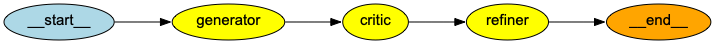

In [8]:
class ReflectionState(TypedDict):
    """Represents the state of our reflection graph."""
    user_request: str
    draft: Optional[dict]
    critique: Optional[dict]
    refined_code: Optional[dict]

# Initialize a new state graph
graph_builder = StateGraph(ReflectionState)

# Add the nodes to the graph
graph_builder.add_node("generator", generator_node)
graph_builder.add_node("critic", critic_node)
graph_builder.add_node("refiner", refiner_node)

# Define the workflow edges as a simple linear sequence
graph_builder.set_entry_point("generator")
graph_builder.add_edge("generator", "critic")
graph_builder.add_edge("critic", "refiner")
graph_builder.add_edge("refiner", END)

# Compile the graph into a runnable application
reflection_app = graph_builder.compile()

print("Reflection graph compiled successfully!")


import importlib, sys
for m in list(sys.modules):
    if m.startswith("langchain_core.runnables.graph"):
        del sys.modules[m]

import pygraphviz

# Visualize the graph
# try:
#     from IPython.display import Image, display
#     png_image = reflection_app.get_graph().draw_png()
#     display(Image(png_image))
# except Exception as e:
#     print(f"Graph visualization failed: {e}. Please ensure pygraphviz is installed.")


try:
    from IPython.display import Image, display
    from langchain_core.runnables.graph_png import PngDrawer
    import pygraphviz as pgv

    drawer = PngDrawer()
    graph = reflection_app.get_graph()

    viz = pgv.AGraph(directed=True, nodesep=0.5, ranksep=0.8, rankdir="LR")
    drawer.add_nodes(viz, graph)
    drawer.add_edges(viz, graph)
    drawer.add_subgraph(viz, [n.split(":") for n in graph.nodes])
    drawer.update_styles(viz, graph)
    png_image = viz.draw(format="png", prog="dot")
    viz.close()

    display(Image(png_image))
except Exception as e:
    print(f"Graph visualization failed: {e}.")

In [9]:
user_request = "Write a Python function to find the nth Fibonacci number."
initial_input = {"user_request": user_request}

console.print(f"[bold cyan]🚀 Kicking off Reflection workflow for request:[/bold cyan] '{user_request}'\n")

# Stream the results and capture the final state
final_state = None
for state_update in reflection_app.stream(initial_input, stream_mode="values"):
    final_state = state_update

console.print("\n[bold green]✅ Reflection workflow complete![/bold green]")

console.print("\n[bold]📝 Draft:[/bold]")
console.print(Syntax(final_state['draft']['code'], "python", theme="monokai", line_numbers=True))
console.print(Markdown(final_state['draft']['explanation']))

console.print("\n[bold]🔍 Critique:[/bold]")
console.print(Markdown(final_state['critique']['critique_summary']))
console.print(f"has_errors: {final_state['critique']['has_errors']}  |  is_efficient: {final_state['critique']['is_efficient']}")
for s in final_state['critique']['suggested_improvements']:
    console.print(f"  • {s}")

console.print("\n[bold]✨ Refined Code:[/bold]")
console.print(Syntax(final_state['refined_code']['refined_code'], "python", theme="monokai", line_numbers=True))
console.print(Markdown(final_state['refined_code']['refinement_summary']))

🚀 Kicking off Reflection workflow for request: 'Write a Python function to find the nth Fibonacci number.'

--- 1. Generating Initial Draft ---

--- 2. Critiquing Draft ---

--- 3. Refining Code ---

✅ Reflection workflow complete!

...

• For very large n, the O(n) loop can be slow; consider fast doubling (O(log n)) if this function needs to handle
extremely large indices.

• Consider adding a small docstring example or doctest to clarify F0=0, F1=1 behavior.

✨ Refined Code:

   1 def fibonacci(n: int) -> int:                                                                                 
   2     """Return the nth Fibonacci number (F0=0, F1=1).                                                          
   3                                                                                                               
   4     This implementation uses fast doubling, so it runs in O(log n) time                                       
   5     and O(1) space (excluding the size of the resulting integers).                                            
   6                                                                                                               
   7     Args:                                                                                                     
   8         n: A non-negative integer index.                                                                      
   9                                                                                                               
  10     Returns:                                                                                                  
  11         The nth Fibonacci number.                                                                             
  12                                                                                                               
  13     Raises:                                                                                                   
  14         TypeError: If n is not an integer, or is a bool (bool is a subclass                                   
  15             of int but is not accepted as a valid Fibonacci index).                                           
  16         ValueError: If n is negative.                                                                         
  17                                                                                                               
  18     Examples:                                                                                                 
  19         >>> fibonacci(0)                                                                                      
  20         0                                                                                                     
  21         >>> fibonacci(1)                                                                                      
  22         1                                                                                                     
  23         >>> fibonacci(10)                                                                                     
  24         55                                                                                                    
  25         >>> fibonacci(20)                                                                                     
  26         6765                                                                                                  
  27     """                                                                                                       
  28     if isinstance(n, bool):                                                                                   
  29         raise TypeError("n must be an integer, not bool")                                                     
  30     if not isinstance(n, int):                                                                                
  31         raise TypeError("n must be an integer")                                                               
  32     if n < 0:                                                                                                 
  33         raise ValueError("n must be non-negative")                                                            
  34                                                                                                               
  35     # Fast doubling: maintain (F(k), F(k+1)) while 

Implemented all suggested improvements: documented the TypeError in the docstring's Raises section; decided to     
reject bool explicitly despite it being an int subclass; replaced the O(n) loop with an iterative fast-doubling    
algorithm for O(log n) time and O(1) space; and added doctest examples demonstrating F0=0, F1=1, and additional    
Fibonacci values.

In [10]:
class CodeEvaluation(BaseModel):
    """Schema for evaluating a piece of code."""
    correctness_score: int = Field(description="Score from 1-10 on whether the code is logically correct.")
    efficiency_score: int = Field(description="Score from 1-10 on the code's algorithmic efficiency.")
    style_score: int = Field(description="Score from 1-10 on code style and readability (PEP 8). ")
    justification: str = Field(description="A brief justification for the scores.")

judge_llm = llm.with_structured_output(CodeEvaluation)

def evaluate_code(code_to_evaluate: str):
    prompt = f"""You are an expert judge of Python code. Evaluate the following function on a scale of 1-10 for correctness, efficiency, and style. Provide a brief justification.
    
    Code:
    ```python
    {code_to_evaluate}
    ```
    """
    return judge_llm.invoke(prompt)

if final_state and 'draft' in final_state and 'refined_code' in final_state:
    console.print("--- Evaluating Initial Draft ---")
    initial_draft_evaluation = evaluate_code(final_state['draft']['code'])
    console.print(initial_draft_evaluation.model_dump()) # Corrected: use .model_dump()

    console.print("\n--- Evaluating Refined Code ---")
    refined_code_evaluation = evaluate_code(final_state['refined_code']['refined_code'])
    console.print(refined_code_evaluation.model_dump()) # Corrected: use .model_dump()
else:
    console.print("[bold red]Error: Cannot perform evaluation because the `final_state` is incomplete.[/bold red]")

--- Evaluating Initial Draft ---

{
    'correctness_score': 10,
    'efficiency_score': 9,
    'style_score': 10,
    'justification': 'The implementation is correct: it validates integer input, rejects negative n, and 
iteratively computes Fibonacci numbers with F0=0 and F1=1. It runs in O(n) time and O(1) space, which is efficient 
and avoids recursion/stack issues; an O(log n) fast-doubling method exists but is unnecessary for most use cases. 
The code is clean, PEP 8-compliant, well-documented, and uses clear variable names and tuple assignment.'
}

--- Evaluating Refined Code ---

{
    'correctness_score': 10,
    'efficiency_score': 10,
    'style_score': 10,
    'justification': 'The fast doubling implementation is mathematically correct: it maintains (F(k), F(k+1)) and 
updates using F(2k)=F(k)*(2F(k+1)-F(k)) and F(2k+1)=F(k)^2+F(k+1)^2, correctly handling the MSB-first bit walk. 
Base cases n=0 and n=1 work, and input validation for bool, non-int, and negative values is appropriate. It runs in
O(log n) iterations with O(1) state (excluding big-integer arithmetic growth), and the docstring is detailed with 
type hints, examples, and error documentation; code is concise and PEP 8-compliant.'
}